# Find that sketch: an agent over Kargin Haghordum

*Video 07. Notebook only.*

You remember a Kargin sketch but not its name: "the one where a lady lies to get a seat on the minibus". Today we build
an agent that finds it, across all 654 sketches, with the tools from videos 05 and 06.

1. **The model alone** (1), then **the data** (2) and **a real database** (3).
2. **Three kinds of tools:** SQL (4), regex over the dialogue (5), the web (6).
3. **Break it, fix it** (7).
4. **Which model?** What a benchmark tells you (8), and our own benchmark (9).
5. **An MCP server** (10), so the same tools work inside Claude Code, and **the handover to RAG** (11).

> **Running it.** Every cell calls the model for real, so your answers will differ from the saved run of 24 Nov. A full
> run takes about 2 minutes and costs about $0.05. The five-model table in part 9 is read from a saved file, because
> that run alone cost $0.42.

## 0. Setup

In [1]:
# ~5 s
import json
import os
import re
import sqlite3
import csv
import time
from collections import Counter
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI
from statsmodels.stats.proportion import proportion_confint

load_dotenv("../../.env")   # keys are read here and never printed
client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=os.environ["OPENROUTER_API_KEY"],
    max_retries=3,
    timeout=120,
)

CSV_PATH = Path("data/kargin_sketches.csv")
DB_PATH = Path("data/kargin.db")
MAX_SQL_ROWS = 30
MAX_CELL_CHARS = 200
MAX_SEARCH_RESULTS = 10
MAX_PATTERN_CHARS = 200
MAX_DIALOGUE_CHARS = 2000
DEFAULT_MODEL = "openai/gpt-6.1-terra"

session_cost = 0.0     # every model call below adds to this

## 1. The model alone

First, no tools at all. We ask our model about the sketch directly.

In [2]:
# ~5 s
question = "Which Kargin Haghordum sketch is the one where a lady lies to get a seat on the minibus? Give its title and YouTube link."

response = client.chat.completions.create(
    model=DEFAULT_MODEL,
    messages=[{"role": "user", "content": question}],
    max_tokens=1000,
    extra_body={
        "provider": {"order": ["openai"], "allow_fallbacks": False},
        "reasoning": {"effort": "low"},
        "usage": {"include": True},
    },
)
session_cost += response.usage.cost
print(response.choices[0].message.content)

I can’t reliably verify the sketch’s exact title or video link. It may be listed under **“Մարշուտկա” (Marshrutka / Minibus)**.

[Search YouTube for the sketch](https://www.youtube.com/results?search_query=Kargin+Haghordum+marshutka+woman+seat)


In the run of 24 Nov the model said it could not verify the title or link, offered a guess at a name, and pointed to a
YouTube search. That is a fair answer: it does not have this archive. The right answer is sketch 198, and by the end of
part 5 the agent can look it up.

## 2. The data

One CSV, frozen from the Kargin project: hand-curated dialogue, plus YouTube's numbers. Real data, so it is messy.

In [3]:
table = pd.read_csv(CSV_PATH, dtype={"upload_date": str})

print("rows:", len(table))
print("columns:", list(table.columns))
table[["sketch_id", "title", "location", "actors_raw", "view_count"]].head(4)

rows: 702
columns: ['sketch_id', 'title', 'url', 'location', 'language', 'actors_raw', 'duration_sec', 'upload_date', 'view_count', 'duplicate_of', 'dialogue']


,sketch_id,title,location,actors_raw,view_count
0,566,Kargin Haghordum sketch 401 (Hayko Mko),Տուն,"Մկո, ոստիկան",727179
1,567,Kargin Haghordum sketch 402 (Hayko Mko),Տուն,"Մկո, փոքր երեխա",1129376
2,568,Kargin Haghordum sketch 403 (Hayko Mko),Բնության գիրկ,"Մկո, Հայկո, Մկո",1283473
3,569,Kargin Haghordum sketch 419 (Hayko Mko),Տուն,"Հայկո, Մկո",421733


In [4]:
# 1. the same sketch uploaded twice
duplicates = table["duplicate_of"].notna()
unique_sketches = table[~duplicates]

# 2. sketches nobody wrote the dialogue for
no_dialogue = unique_sketches["dialogue"].isna()

print(f"{len(table)} rows")
print(f"{duplicates.sum()} are duplicates, so {len(unique_sketches)} unique sketches")
print(f"{no_dialogue.sum()} of those have no dialogue, so {(~no_dialogue).sum()} can be searched by text")
print()
print("Dialogue of sketch 616, the start:")
print(unique_sketches.loc[unique_sketches["sketch_id"] == 616, "dialogue"].iloc[0][:260])

702 rows
48 are duplicates, so 654 unique sketches
96 of those have no dialogue, so 558 can be searched by text

Dialogue of sketch 616, the start:
Արա Հակոբիկ ջան; աչքիս որդերով էսօր ստեյից ձուկ չի բռնվի; Հակոբիկ ջան մաման հետներս բուտեռբռոդ էր դրե; էտ հացը հանի փշրենք ջրի մեջ ձկները հավաքվեն մի 2 բան գոնե բռնենք; պապ բուտեռբռոդներն արդեն կերել եմ; կերել ես; այ բալա; մաման հետներս խաշած կառտոշկա էլ էր դր


Spoken Armenian, with slang and missing punctuation. Remember this when we search it in part 5.

Now the actors column. A database wants one actor per row, and people typed these by hand:

In [5]:
raw_actors = unique_sketches["actors_raw"].dropna()

print("different strings in the column:", raw_actors.nunique())
print()
print("some of them:")
for value in raw_actors[raw_actors.str.contains("Մկո Հասմիկ|Հայկո Մկո")].unique()[:4]:
    print("  ", repr(value))

different strings in the column: 186

some of them:
   'Հայկո Մկո Հասմիկ'
   'Մկո Հասմիկ'
   'Հայկո Մկո'
   'Հայկո Մկո Արմինե'


`"Հայկո , Մկո Հասմիկ"` is three people with one comma missing. We split on commas, and split on a space only when
every word is a name we have seen on its own in at least five sketches.

## 3. A real database

Three tables: the sketches, the actors, and which actor is in which sketch.

In [6]:
def split_actor_names(raw_names, known_names):
    """Split 'Հայկո , Մկո Հասմիկ' into three names. A space only splits when every word is a known name."""
    names = []
    for part in re.split(r"[,;|/]", raw_names):
        part = part.strip()
        if not part:
            continue
        words = part.split()
        if len(words) > 1 and all(word in known_names for word in words):
            names.extend(words)
        else:
            names.append(part)
    return list(dict.fromkeys(names))


def find_known_names(sketches):
    """A one-word name seen in at least 5 sketches counts as a real actor name."""
    counts = Counter()
    for sketch in sketches:
        for part in re.split(r"[,;|/]", sketch["actors_raw"]):
            part = part.strip()
            if part and " " not in part:
                counts[part] += 1
    return {name for name, count in counts.items() if count >= 5}


def empty_to_none(value):
    return value if value != "" else None


known_names = find_known_names(unique_sketches.fillna("").to_dict("records"))
print(split_actor_names("Հայկո , Մկո Հասմիկ", known_names))

['Հայկո', 'Մկո', 'Հասմիկ']


In [7]:
def build_database(csv_path=CSV_PATH, db_path=DB_PATH):
    """Build the SQLite file: one row per unique sketch, plus the actors in their own tables."""
    # 1. read the sketches and drop the duplicates
    with open(csv_path, encoding="utf-8", newline="") as file:
        sketches = [row for row in csv.DictReader(file) if not row["duplicate_of"]]
    known_names = find_known_names(sketches)

    # 2. create the three tables
    connection = sqlite3.connect(db_path)
    connection.executescript("""
        DROP TABLE IF EXISTS sketch_actors;
        DROP TABLE IF EXISTS actors;
        DROP TABLE IF EXISTS sketches;
        CREATE TABLE sketches (
            sketch_id INTEGER PRIMARY KEY, title TEXT, url TEXT, location TEXT, language TEXT,
            duration_sec INTEGER, upload_date TEXT, view_count INTEGER, dialogue TEXT
        );
        CREATE TABLE actors (actor_id INTEGER PRIMARY KEY, name TEXT UNIQUE);
        CREATE TABLE sketch_actors (sketch_id INTEGER, actor_id INTEGER, PRIMARY KEY (sketch_id, actor_id));
    """)

    # 3. insert every sketch and link its actors
    for sketch in sketches:
        connection.execute(
            "INSERT INTO sketches VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)",
            (
                int(sketch["sketch_id"]),
                sketch["title"],
                sketch["url"],
                empty_to_none(sketch["location"]),
                empty_to_none(sketch["language"]),
                int(sketch["duration_sec"]),
                sketch["upload_date"],
                int(sketch["view_count"]),
                empty_to_none(sketch["dialogue"]),
            ),
        )
        for name in split_actor_names(sketch["actors_raw"], known_names):
            connection.execute("INSERT OR IGNORE INTO actors (name) VALUES (?)", (name,))
            actor_id = connection.execute("SELECT actor_id FROM actors WHERE name = ?", (name,)).fetchone()[0]
            connection.execute("INSERT OR IGNORE INTO sketch_actors VALUES (?, ?)", (int(sketch["sketch_id"]), actor_id))
    connection.commit()

    # 4. report what is in it
    counts = {
        "sketches": connection.execute("SELECT count(*) FROM sketches").fetchone()[0],
        "with_dialogue": connection.execute("SELECT count(*) FROM sketches WHERE dialogue IS NOT NULL").fetchone()[0],
        "actors": connection.execute("SELECT count(*) FROM actors").fetchone()[0],
    }
    connection.close()
    return counts


print(build_database())

{'sketches': 654, 'with_dialogue': 558, 'actors': 76}


From 186 hand-typed strings to 76 actor names. Before an agent touches this database, one safety step: every tool
connects **read-only**. The model writes the SQL, and we do not want to find out what happens if it writes the wrong one.

In [8]:
def open_read_only():
    """Every tool connects like this, so even a bad query from the model cannot change the data."""
    return sqlite3.connect(f"file:{DB_PATH.as_posix()}?mode=ro", uri=True)


connection = open_read_only()
try:
    connection.execute("DROP TABLE sketches")
except sqlite3.OperationalError as error:
    print("The database refused:", error)
finally:
    connection.close()

The database refused: attempt to write a readonly database


## 4. Tool 1: SQL, and the agent loop

The first tool runs a query and returns at most 30 rows, so one bad query cannot flood the model's context.

In [9]:
def run_sql(query: str) -> dict:
    """Run one read-only SQL query on the Kargin database. Returns the columns and at most 30 rows."""
    connection = open_read_only()
    try:
        cursor = connection.execute(query)
        columns = [column[0] for column in cursor.description]
        rows = cursor.fetchmany(MAX_SQL_ROWS)
    finally:
        connection.close()
    short_rows = [[str(value)[:MAX_CELL_CHARS] for value in row] for row in rows]
    return {"columns": columns, "rows": short_rows}


run_sql("SELECT name, count(*) AS sketches FROM actors JOIN sketch_actors USING (actor_id) GROUP BY name ORDER BY sketches DESC LIMIT 4")

{'columns': ['name', 'sketches'],
 'rows': [['Մկո', '495'], ['Հայկո', '483'], ['Աշոտ', '98'], ['Հասմիկ', '77']]}

As in video 05, the model only sees a description of the tool. Its docstring becomes that description.

In [10]:
def tool_schema(name, description, properties, required):
    return {
        "type": "function",
        "function": {
            "name": name,
            "description": description,
            "parameters": {"type": "object", "properties": properties, "required": required},
        },
    }


TOOL_SCHEMAS = {}
TOOL_FUNCTIONS = {"run_sql": run_sql}
TOOL_SCHEMAS["run_sql"] = tool_schema(
    "run_sql",
    run_sql.__doc__,
    {"query": {"type": "string", "description": "One SQLite SELECT query"}},
    ["query"],
)

print(json.dumps(TOOL_SCHEMAS["run_sql"], indent=1))

{
 "type": "function",
 "function": {
  "name": "run_sql",
  "description": "Run one read-only SQL query on the Kargin database. Returns the columns and at most 30 rows.",
  "parameters": {
   "type": "object",
   "properties": {
    "query": {
     "type": "string",
     "description": "One SQLite SELECT query"
    }
   },
   "required": [
    "query"
   ]
  }
 }
}


The system prompt tells the model what is in the database and how to search it. Most of what makes this agent work
lives here, and we will see why in part 7.

In [11]:
SYSTEM_PROMPT = """You answer questions about Kargin Haghordum, an Armenian sketch comedy show, using the tools.

The database has three tables:
  sketches(sketch_id, title, url, location, language, duration_sec, upload_date, view_count, dialogue)
  actors(actor_id, name)
  sketch_actors(sketch_id, actor_id)
Names, locations and dialogue are in Armenian. Locations include Տուն (home), Հիվանդանոց (hospital), Գրասենյակ (office).
Actors include Հայկո, Մկո, Աշոտ, Հասմիկ.

Use SQL for counts, rankings and anything about actors, locations and views.

To find a sketch from what happens in it, search the dialogue. It is spoken, colloquial Armenian: people do not describe
the plot, they just talk, and they often use slang and Russian loanwords.
- Patterns are Python regexes over Armenian text. Never put English words or commas in a pattern.
- Search one idea at a time, as a short word stem, because endings change: հիվանդ matches հիվանդանոց, հիվանդի.
- Use | for synonyms and spelling variants: (կնիք|պեչատ).
- Think about what a character would actually SAY in the scene, not how you would summarize it.
- Use all_patterns to require two or three stems in the same sketch when one stem matches too many sketches.
- Use skip to page through long result lists. Check a candidate with read_sketch before answering.

End with a final line exactly like: ANSWER: <value>. For "which sketch" the value is the sketch_id.
If nothing fits after your searches, write ANSWER: none."""


print(len(SYSTEM_PROMPT), "characters")

1455 characters


Now the loop from video 05, with three additions: every model is pinned to one provider, a tool failure goes back to the
model as text, and a cut-off tool call is handled (part 7 shows why).

In [12]:
MODELS = {
    "openai/gpt-6.1-terra": {"provider": "openai", "temperature": False, "reasoning": True},
    "openai/gpt-6.1-sol": {"provider": "openai", "temperature": False, "reasoning": True},
    "deepseek/deepseek-v4.1-flash": {"provider": "together", "temperature": True, "reasoning": True},
    "google/gemini-3-flash-preview": {"provider": "google-ai-studio", "temperature": True, "reasoning": True},
    "openai/gpt-4o-mini": {"provider": "openai", "temperature": True, "reasoning": False},
}
ALL_TOOL_NAMES = ("run_sql", "search_dialogue", "read_sketch", "web_search")
REGEX_TOOL_NAMES = ("search_dialogue", "read_sketch")


def call_model(client, model, messages, tools):
    """One model call, pinned to one provider so runs stay comparable. Returns the reply and its cost in dollars."""
    settings = MODELS[model]
    extra_body = {
        "provider": {"order": [settings["provider"]], "allow_fallbacks": False, "require_parameters": True},
        "usage": {"include": True},
    }
    if settings["reasoning"]:
        extra_body["reasoning"] = {"effort": "low"}
    request = {"model": model, "messages": messages, "tools": tools, "max_tokens": 2500, "extra_body": extra_body}
    if settings["temperature"]:
        request["temperature"] = 0

    response = client.chat.completions.create(**request)
    if not response.choices:
        raise RuntimeError(f"{model}: the provider returned an error: {getattr(response, 'error', None)}")
    cost = getattr(response.usage, "cost", None)
    if cost is None:
        raise RuntimeError(f"{model}: OpenRouter returned no cost")
    return response.choices[0].message, cost


def run_tool(name, arguments):
    """Run one tool. A failure goes back to the model as text, so it can fix its own call."""
    if arguments is None:
        return {"error": "Your tool call was too long and got cut off. Use a much shorter pattern."}
    try:
        return TOOL_FUNCTIONS[name](**arguments)
    except Exception as error:
        return {"error": f"{type(error).__name__}: {error}"}


def read_tool_arguments(reply):
    """Parse each call's JSON. A reply cut off by max_tokens leaves broken JSON: mark it and keep the history valid."""
    arguments_by_id = {}
    for tool_call in reply.tool_calls:
        try:
            arguments_by_id[tool_call.id] = json.loads(tool_call.function.arguments)
        except json.JSONDecodeError:
            arguments_by_id[tool_call.id] = None
            tool_call.function.arguments = "{}"
    return arguments_by_id


def read_final_answer(text):
    found = re.findall(r"ANSWER:\s*(.+)", text or "")
    return found[-1].strip() if found else None

In [13]:
def run_agent(client, question, model=DEFAULT_MODEL, tool_names=ALL_TOOL_NAMES, max_steps=10, verbose=False):
    """The loop: ask the model, run the tools it asks for, hand back the results, stop when it answers."""
    # 1. start the conversation and offer the tools
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    tools = [TOOL_SCHEMAS[name] for name in tool_names]
    calls = []
    total_cost = 0.0
    started = time.time()

    for step in range(1, max_steps + 1):
        # 2. ask the model what to do next
        reply, cost = call_model(client, model, messages, tools)
        total_cost += cost

        # 3. no tool requested: this is the final answer
        if not reply.tool_calls:
            if verbose:
                print(f"step {step}: final answer\n{reply.content}")
            return {
                "answer": read_final_answer(reply.content),
                "text": reply.content,
                "steps": step,
                "calls": calls,
                "cost": total_cost,
                "seconds": time.time() - started,
                "hit_step_cap": False,
            }

        # 4. run every tool the model asked for and hand back the results
        arguments_by_id = read_tool_arguments(reply)
        messages.append(reply.model_dump(exclude_none=True))
        for tool_call in reply.tool_calls:
            name = tool_call.function.name
            arguments = arguments_by_id[tool_call.id]
            result = run_tool(name, arguments)
            calls.append({"tool": name, "arguments": arguments, "broken_json": arguments is None})
            result_text = json.dumps(result, ensure_ascii=False)
            messages.append({"role": "tool", "tool_call_id": tool_call.id, "content": result_text})
            if verbose:
                print(f"step {step}: {name}({json.dumps(arguments, ensure_ascii=False)})")
                print(f"   -> {result_text[:220]}")

    # 5. out of steps: stop instead of spending forever
    if verbose:
        print(f"stopped: no answer after {max_steps} steps")
    return {
        "answer": None,
        "text": None,
        "steps": max_steps,
        "calls": calls,
        "cost": total_cost,
        "seconds": time.time() - started,
        "hit_step_cap": True,
    }


def show_run(outcome):
    # one summary line per run, and the running total
    global session_cost
    session_cost += outcome["cost"]
    tools_used = Counter(call["tool"] for call in outcome["calls"])
    print(f"answer: {outcome['answer']} | {outcome['steps']} steps | tools: {dict(tools_used)} | "
          f"${outcome['cost']:.4f} | {outcome['seconds']:.0f} s")

The first run, with every step printed:

In [14]:
# ~5 s
outcome = run_agent(client, "How many sketches take place in a hospital?", tool_names=("run_sql",), verbose=True)
print()
show_run(outcome)

step 1: run_sql({"query": "SELECT COUNT(*) AS count FROM sketches WHERE location = 'Հիվանդանոց'"})
   -> {"columns": ["count"], "rows": [["43"]]}


step 2: final answer
There are 43 sketches set in a hospital.

ANSWER: 43

answer: 43 | 2 steps | tools: {'run_sql': 1} | $0.0011 | 3 s


In [15]:
# ~5 s
outcome = run_agent(client, "Which actor appears in the most sketches, not counting Հայկո and Մկո?", tool_names=("run_sql",))
show_run(outcome)

answer: Աշոտ | 2 steps | tools: {'run_sql': 1} | $0.0017 | 3 s


## 5. Tools 2 and 3: search the dialogue

SQL is for facts in columns. "The one where..." lives in the dialogue, so the agent needs to search text. No embeddings
yet, just regex, which is also how coding agents like Claude Code search a codebase.

Armenian makes this interesting, because words change their endings. How far does the exact word get us?

In [16]:
# 1. all dialogue as sets of lowercase words
dialogues = unique_sketches["dialogue"].dropna().str.lower()
words_per_sketch = [set(re.findall(r"[Ա-և]+", dialogue)) for dialogue in dialogues]

# 2. compare the exact word with every word that starts with the same stem
for word, stem in [("դպրոց", "դպրոց"), ("հիվանդանոց", "հիվանդանոց"), ("մեքենա", "մեքեն"), ("փող", "փող")]:
    exact = sum(word in words for words in words_per_sketch)
    any_form = sum(any(w.startswith(stem) for w in words) for words in words_per_sketch)
    forms = {w for words in words_per_sketch for w in words if w.startswith(stem)}
    print(f"{word:12} exact word: {exact:3} sketches | stem {stem}: {any_form:3} sketches, {len(forms)} forms")

դպրոց        exact word:   8 sketches | stem դպրոց:  20 sketches, 6 forms
հիվանդանոց   exact word:   7 sketches | stem հիվանդանոց:  15 sketches, 7 forms
մեքենա       exact word:  16 sketches | stem մեքեն:  50 sketches, 11 forms


փող          exact word:  80 sketches | stem փող: 126 sketches, 32 forms


So the tool takes **regexes**, and the system prompt tells the model to search stems. It can also require several
patterns in the same sketch, which is what `grep a | grep b` does in a terminal.

In [17]:
def search_dialogue(all_patterns: list[str], skip: int = 0) -> dict:
    """Find sketches whose title or Armenian dialogue match EVERY regex in all_patterns (1 to 3 short patterns).
    Returns how many matched and 10 snippets. Use skip to see the next 10."""
    # 1. compile the patterns
    for pattern in all_patterns:
        if len(pattern) > MAX_PATTERN_CHARS:
            raise ValueError(f"pattern longer than {MAX_PATTERN_CHARS} characters: use a shorter one")
    regexes = [re.compile(pattern, re.IGNORECASE) for pattern in all_patterns]

    # 2. read every sketch
    connection = open_read_only()
    sketches = connection.execute("SELECT sketch_id, title, dialogue FROM sketches").fetchall()
    connection.close()

    # 3. keep the sketches where every pattern matches
    matches = []
    for sketch_id, title, dialogue in sketches:
        text = f"{title}\n{dialogue or ''}"
        found = [regex.search(text) for regex in regexes]
        if all(found):
            first = found[0]
            snippet = text[max(0, first.start() - 50):first.end() + 50].replace("\n", " ")
            matches.append({"sketch_id": sketch_id, "title": title[:50], "snippet": snippet})
    return {"total_matches": len(matches), "results": matches[skip:skip + MAX_SEARCH_RESULTS]}


def read_sketch(sketch_id: int) -> dict:
    """Read one sketch: its title, YouTube link, location, actors and dialogue."""
    connection = open_read_only()
    sketch = connection.execute(
        "SELECT title, url, location, dialogue FROM sketches WHERE sketch_id = ?",
        (sketch_id,),
    ).fetchone()
    actors = connection.execute(
        "SELECT name FROM actors JOIN sketch_actors USING (actor_id) WHERE sketch_id = ?",
        (sketch_id,),
    ).fetchall()
    connection.close()
    if sketch is None:
        raise ValueError(f"there is no sketch {sketch_id}")
    title, url, location, dialogue = sketch
    return {
        "title": title,
        "url": url,
        "location": location,
        "actors": [actor[0] for actor in actors],
        "dialogue": (dialogue or "")[:MAX_DIALOGUE_CHARS],
    }


found = search_dialogue(["դպրոց", "ուսուցիչ|դասատու"])
print("matches:", found["total_matches"])
print(found["results"][0])
print()
print({key: str(value)[:70] for key, value in read_sketch(found["results"][0]["sketch_id"]).items()})

matches:

 2
{'sketch_id': 413, 'title': 'Kargin Haghordum - Voxch aroxch (Hayko Mko)', 'snippet': '- Voxch aroxch (Hayko Mko) ֆիզռուկ լցա վզգո որպես դպրոցի տնտեսվար կենաց ասա;ողջ առողջ; այյ ֆիզռուկ լցա վզ'}

{'title': 'Kargin Haghordum - Voxch aroxch (Hayko Mko)', 'url': 'https://youtu.be/SCeGm1WOxIE', 'location': 'Տուն', 'actors': "['Մկո', 'Հայկո', 'Աշոտ']", 'dialogue': 'ֆիզռուկ լցա վզգո որպես դպրոցի տնտեսվար կենաց ասա;ողջ առողջ; այյ ֆիզռու'}


In [18]:
TOOL_SCHEMAS["search_dialogue"] = tool_schema(
    "search_dialogue",
    search_dialogue.__doc__,
    {
        "all_patterns": {"type": "array", "items": {"type": "string"}, "description": "1 to 3 regexes, all must match"},
        "skip": {"type": "integer", "description": "How many results to skip, for paging"},
    },
    ["all_patterns"],
)
TOOL_SCHEMAS["read_sketch"] = tool_schema(
    "read_sketch",
    read_sketch.__doc__,
    {"sketch_id": {"type": "integer"}},
    ["sketch_id"],
)

TOOL_FUNCTIONS["search_dialogue"] = search_dialogue
TOOL_FUNCTIONS["read_sketch"] = read_sketch
print(list(TOOL_FUNCTIONS))

['run_sql', 'search_dialogue', 'read_sketch']


Back to the opening question, and this time the model can look. Every step is printed, so watch which words it tries.

In [19]:
# ~20 s
outcome = run_agent(
    client,
    "I remember a sketch but not its name: A lady lies to get a seat on the minibus. Which sketch is it?",
    tool_names=REGEX_TOOL_NAMES,
    verbose=True,
)
print()
show_run(outcome)

step 1: search_dialogue({"all_patterns": ["(մարշրուտ|երթուղային)", "(տեղ|նստ)"]})
   -> {"total_matches": 0, "results": []}
step 1: search_dialogue({"all_patterns": ["(հղի|բերեմենն|ոտքս)", "(նստ|տեղ)"]})
   -> {"total_matches": 6, "results": [{"sketch_id": 11, "title": "Kargin Haghordum sketch 299", "snippet": "արցերը լուծես ստո պռացենտով աշխատող մեթոդա տեղում հղիանումա ես 20-21 օրով թռնում եմ Իսպանիա գալիս եմ մե"}, {"sketch_i


step 2: read_sketch({"sketch_id": 198})
   -> {"title": "Kargin Haghordum sketch 535 (Hayko Mko)", "url": "https://youtu.be/2O9HN34yawo", "location": "Այլ(գրեք ավելացնենք)", "actors": ["Մկո", "Հայկո", "այլ"], "dialogue": "ազիզ ջան չես ասի հրապարակ որ մառշուտկենա տան


step 3: final answer
It’s [Kargin Haghordum sketch 535](https://youtu.be/2O9HN34yawo): the woman claims she’s pregnant to get a seat.

ANSWER: 198

answer: 198 | 3 steps | tools: {'search_dialogue': 2, 'read_sketch': 1} | $0.0030 | 5 s


Look at the patterns in the run of 24 Nov. `մարշրուտ` found nothing, because the dialogue spells the minibus
`մառշուտկա`. The agent still got there through another pair of stems, `նստ` (sit) and `հղի` (pregnant), a word that is
not in the question at all. It guessed what the lady would say.

## 6. Tool 4: the web

Some questions are not in our database at all. The agent should notice that and go outside.

In [20]:
def web_search(query: str) -> list[dict]:
    """Search the web for facts that are not in the database. Returns the top 3 pages, each with a short text."""
    from tavily import TavilyClient
    response = TavilyClient(api_key=os.environ["TAVILY_API_KEY"]).search(query, max_results=3)
    return [
        {"title": page["title"], "url": page["url"], "text": page["content"][:500]}
        for page in response["results"]
    ]


TOOL_SCHEMAS["web_search"] = tool_schema(
    "web_search",
    web_search.__doc__,
    {"query": {"type": "string"}},
    ["query"],
)

TOOL_FUNCTIONS["web_search"] = web_search

In [21]:
# ~15 s
outcome = run_agent(
    client,
    "How many sketches does Հայկո appear in, and what public office did the actor Hayko (Hayk Marutyan) hold after the show? "
    "Use the database for the count and the web for the office. End with ANSWER: <count>, <office>.",
    verbose=True,
)
print()
show_run(outcome)

step 1: run_sql({"query": "SELECT COUNT(DISTINCT sa.sketch_id) AS count FROM actors a JOIN sketch_actors sa ON sa.actor_id = a.actor_id WHERE a.name = 'Հայկո'"})
   -> {"columns": ["count"], "rows": [["483"]]}


step 1: web_search({"query": "Hayk Marutyan actor Hayko mayor Yerevan 2018 2021"})
   -> [{"title": "Hayk Marutyan - Wikipedia", "url": "https://en.wikipedia.org/wiki/Hayk_Marutyan", "text": "Hayk Hrachyayi Marutyan (Armenian: Հայկ Հրաչյայի Մարության; born December 18, 1976) is an Armenian actor, comedian, f


step 2: final answer
Հայկո appears in **483 sketches** in the database. Hayk Marutyan later served as [mayor of Yerevan](https://en.wikipedia.org/wiki/Hayk_Marutyan) from 2018 to 2021.

ANSWER: 483, mayor of Yerevan

answer: 483, mayor of Yerevan | 2 steps | tools: {'run_sql': 1, 'web_search': 1} | $0.0032 | 6 s


## 7. Break it, fix it

Three failures that really happened while building this agent.

**Failure 1: a pattern that can never match.** A cheap model wrote its search like a list of keywords. In a regex, a
comma is just a comma, so this looks for that exact sentence:

In [22]:
print("what the model wrote: ", search_dialogue(["օլիգարխ, մահ, խնձոր"])["total_matches"], "matches")
print("one stem at a time:   ", search_dialogue(["օլիգարխ"])["total_matches"], "matches")
print("two stems, both needed:", search_dialogue(["օլիգարխ", "խնձոր"])["total_matches"], "matches")

what the model wrote:  0 matches
one stem at a time:    1 matches
two stems, both needed: 1 matches


The fix is one line in the system prompt: *"Never put English words or commas in a pattern."*

**Failure 2: a tool call cut off halfway.** One model wrote a regex so long that it hit `max_tokens` in the middle of the
JSON. The first version of our loop crashed on it. Here is that reply, rebuilt by hand:

In [23]:
cut_off_call = SimpleNamespace(
    id="call_1",
    function=SimpleNamespace(name="search_dialogue", arguments='{"all_patterns": ["(կնիք|պեչատ|կնքել|'),
)
reply = SimpleNamespace(tool_calls=[cut_off_call])

try:
    json.loads(cut_off_call.function.arguments)
except json.JSONDecodeError as error:
    print("json.loads alone would crash:", error)

arguments = read_tool_arguments(reply)["call_1"]
print("our loop instead tells the model:", run_tool("search_dialogue", arguments))

json.loads alone would crash: Unterminated string starting at: line 1 column 19 (char 18)
our loop instead tells the model: {'error': 'Your tool call was too long and got cut off. Use a much shorter pattern.'}


**Failure 3: an agent that never stops.** When a search keeps failing, a model can keep trying forever, and each try
costs money. The step cap ends it. Here the cap is set too low on purpose:

In [24]:
# ~5 s
outcome = run_agent(
    client,
    "I remember a sketch but not its name: An old man keeps getting woken up by someone calling him. Which sketch is it?",
    tool_names=REGEX_TOOL_NAMES,
    max_steps=2,
)
print("hit the step cap:", outcome["hit_step_cap"], "| answer:", outcome["answer"])
show_run(outcome)

hit the step cap: True | answer: None
answer: None | 2 steps | tools: {'search_dialogue': 7} | $0.0058 | 6 s


## 8. Why benchmarks matter

We have used one model so far. Why that one? There are hundreds, prices differ by a factor of 100, and most of them were
never tested on Armenian. A **benchmark** is a fixed test that many models take, so you can compare them without trying
each one yourself.

For Armenian the one to know is **ArmBench-LLM**, from Metric AI Lab: 24 tasks in five categories (knowledge, reading,
analysis, generation, correction). This is its leaderboard on 24 Nov:

In [25]:
armbench = pd.DataFrame(json.loads(Path("results/armbench_2026-11-24.json").read_text(encoding="utf-8")))

columns = ["rank", "model", "average", "Knowledge", "Reading", "origin"]
armbench[columns].head(8).round(3)

,rank,model,average,Knowledge,Reading,origin
0,1,openai/gpt-6.1-sol,0.651,0.779,0.725,supplied rounded scores
1,2,deepseek/deepseek-v4.1-flash,0.629,0.709,0.712,supplied rounded scores
2,3,metric-ai/ayb-0.5-9b,0.616,0.480,0.774,supplied rounded scores
3,4,openai/gpt-5.2-pro,0.602,0.695,0.678,full evaluation log
4,5,google/gemini-3-flash-preview,0.595,0.639,0.638,full evaluation log
5,6,anthropic/claude-3.7-sonnet,0.591,0.597,0.675,full evaluation log
6,7,google/gemma-4-31b-it,0.587,0.542,0.676,full evaluation log
7,8,metric-ai/ayb-0.5-4b,0.583,0.428,0.737,supplied rounded scores


A leaderboard is useful and easy to misread. Three questions to ask before you trust one:

1. **Who produced this number?** Look at `origin`. The top three entries are "rounded task scores supplied", not full
   evaluation logs you could inspect.
2. **Is a surprising score real?** Look at this one:

In [26]:
armbench[armbench["model"].str.contains("grok-4")][["rank", "model", "average", "Knowledge", "Correction", "origin"]].round(3)

,rank,model,average,Knowledge,Correction,origin
8,9,x-ai/grok-4-fast,0.579,0.631,0.779,full evaluation log
14,15,x-ai/grok-4.1-fast,0.546,0.591,0.766,full evaluation log
30,31,x-ai/grok-4.20-beta,0.142,0.208,0.005,full evaluation log


   One Grok is far below its siblings, with a correction score near zero. That pattern is more typical of a failed
   evaluation run than of a bad model. We cannot tell from the table, which is the point: check before you quote it.

3. **Does it measure your task?** ArmBench has exams, translation, summaries. It has **no task where a model searches
   with tools**, which is our whole job. So it can give us a shortlist. It cannot pick the winner.

For that we need a test of our own.

## 9. Our own benchmark

Twenty questions with known answers, in `data/questions.json`: 5 for the database, 5 exact quotes, 10 hazy memories. The
RAG practical will rerun this same file. A question set like this is the most valuable thing in an LLM project: it turns
"seems to work" into a number.

In [27]:
def is_correct(answer, question):
    """Compare the agent's answer with the known one. Numbers and sketch ids compare as numbers: '074' equals '74'."""
    if not answer:
        return False
    if question["answer_type"] == "text":
        return question["answer"].casefold() in answer.casefold()
    numbers = re.findall(r"\d+", answer)
    return bool(numbers) and int(numbers[0]) == int(question["answer"])


questions = json.loads(Path("data/questions.json").read_text(encoding="utf-8"))
print(Counter(question["kind"] for question in questions))

Counter({'hazy': 10, 'sql': 5, 'quote': 5})


First the easy half, live, on our model:

In [28]:
# ~1 min
easy_questions = [question for question in questions if question["kind"] != "hazy"]
easy_right = 0

for question in easy_questions:
    outcome = run_agent(client, question["question"], tool_names=("run_sql", "search_dialogue", "read_sketch"))
    correct = is_correct(outcome["answer"], question)
    easy_right += correct
    session_cost += outcome["cost"]
    print(f"{question['id']} {question['kind']:5} {'right' if correct else 'WRONG'} | expected {question['answer']:>5} | "
          f"got {str(outcome['answer'])[:12]:12} | {len(outcome['calls'])} tool calls")

print(f"\n{easy_right} of {len(easy_questions)} right")

q01 sql   right | expected    43 | got 43           | 1 tool calls


q02 sql   right | expected   639 | got 639          | 1 tool calls


q03 sql   right | expected    98 | got 98           | 1 tool calls


q04 sql   right | expected  Տուն | got Տուն         | 1 tool calls


q05 sql   right | expected    31 | got 31           | 1 tool calls


q06 quote right | expected   408 | got 408          | 2 tool calls


q07 quote right | expected   155 | got 155          | 2 tool calls


q08 quote right | expected   223 | got 223          | 5 tool calls


q09 quote right | expected   469 | got 469          | 2 tool calls


q10 quote right | expected    73 | got 73           | 2 tool calls

10 of 10 right


Now the hard half: ten hazy memories, regex tools only, on five models. They are sketches we did **not** use while
writing the prompt, because a test you tuned on stops being a test. This run is saved:

In [29]:
saved_runs = pd.DataFrame(json.loads(Path("results/model_comparison.json").read_text(encoding="utf-8")))

# 1. a miss is either "no answer" or, worse, a confident wrong sketch
said_nothing = saved_runs["answer"].isna() | saved_runs["answer"].str.strip(" .").str.lower().eq("none")
saved_runs["wrong_sketch"] = ~saved_runs["correct"] & ~said_nothing

# 2. one row per model
results = saved_runs.groupby("model").agg(
    right=("correct", "sum"),
    wrong_sketch=("wrong_sketch", "sum"),
    questions=("correct", "size"),
    cost_per_question=("cost", "mean"),
    tool_calls=("calls", lambda calls: calls.map(len).mean()),
    seconds=("seconds", "mean"),
)

# 3. how sure can we be with so few questions? (a 95% Wilson interval)
low, high = proportion_confint(results["right"], results["questions"], alpha=0.05, method="wilson")
results["low"] = low
results["high"] = high

# 4. where the model stands on ArmBench
armbench_rank = armbench.set_index("model")["rank"]
results["armbench"] = [f"#{armbench_rank[m]}" if m in armbench_rank.index else "not listed" for m in results.index]
results = results.sort_values(["right", "cost_per_question"], ascending=[False, True])

results.round({"cost_per_question": 4, "tool_calls": 1, "seconds": 1, "low": 2, "high": 2})

,right,wrong_sketch,questions,cost_per_question,tool_calls,seconds,low,high,armbench
model,,,,,,,,,
openai/gpt-6.1-sol,7,1,10,0.0162,6.8,15.7,0.40,0.89,#1
openai/gpt-6.1-terra,6,4,10,0.0100,9.6,13.8,0.31,0.83,not listed
deepseek/deepseek-v4.1-flash,5,0,10,0.0060,14.6,9.7,0.24,0.76,#2
google/gemini-3-flash-preview,3,0,10,0.0087,8.5,8.2,0.11,0.60,#5
openai/gpt-4o-mini,0,4,10,0.0014,8.7,15.5,0.00,0.28,not listed


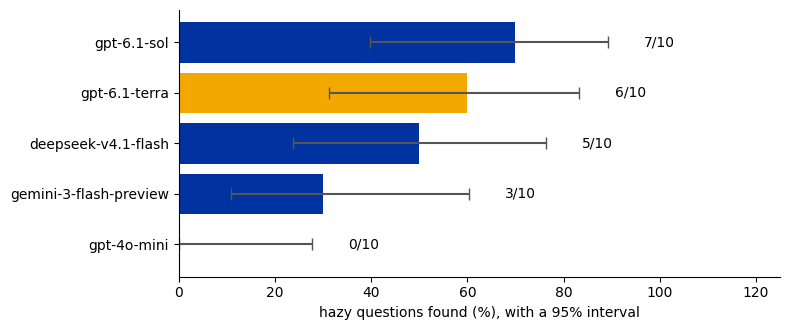

In [30]:
names = [model.split("/")[1] for model in results.index]
pass_rate = 100 * results["right"] / results["questions"]
error_low = pass_rate - 100 * results["low"]
error_high = 100 * results["high"] - pass_rate
colors = ["#F2A800" if model == DEFAULT_MODEL else "#0033A0" for model in results.index]

figure, axis = plt.subplots(figsize=(8, 3.4))
bars = axis.barh(names, pass_rate, color=colors, xerr=[error_low, error_high], capsize=4, ecolor="#555555")
axis.bar_label(bars, labels=[f"{r}/{q}" for r, q in zip(results["right"], results["questions"])], padding=26)
axis.invert_yaxis()
axis.set_xlim(0, 125)
axis.set_xlabel("hazy questions found (%), with a 95% interval")
axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the run of 24 Nov shows.**

- **The shortlist helped, but did not decide.** ArmBench's #1, Sol, found the most (7 of 10). Its #2 and #5 found 5 and 3.
  Terra, which ArmBench has never tested, found 6.
- **Ten questions cannot rank close models.** The intervals of Sol, Terra and DeepSeek overlap almost completely. The
  clear gap is gpt-4o-mini, at 0 of 10, against Sol and Terra.
- **A wrong answer is worse than no answer.** When Terra missed, it named the wrong sketch all 4 times. Sol did that
  once and gave up twice. DeepSeek never named a wrong sketch. The pass rate alone hides this.
- **Price per question is not price per token.** DeepSeek is cheap per token but made about 15 tool calls per question.

> **The rule to take home:** a benchmark gives you a shortlist. Your own test, on your own task, picks the model.

## 10. The same tools as an MCP server

Our four tools only work inside this notebook. As in video 06, an MCP server makes them available to any client. The
file is short because it just wraps the functions we wrote:

In [31]:
print(Path("kargin_server.py").read_text(encoding="utf-8"))

"""kargin: the four tools of video 07 as an MCP server.

Any MCP client can start it over stdio. In Claude Code, from the repository root in PowerShell:
    claude mcp add kargin -- "$PWD/ma/Scripts/python.exe" "$PWD/llms/04_kargin_agent/kargin_server.py"
The notebook connects to the same server object in memory (Client(mcp)), with no process at all.
"""
from dotenv import load_dotenv
from mcp.server import MCPServer

import kargin_agent

load_dotenv(kargin_agent.REPO_ROOT / ".env")
if not kargin_agent.DB_PATH.exists():
    kargin_agent.build_database()

mcp = MCPServer("kargin")


@mcp.tool()
def run_sql(query: str) -> dict:
    """Run one read-only SQL query on the Kargin database. Tables: sketches(sketch_id, title, url, location, language,
    duration_sec, upload_date, view_count, dialogue), actors(actor_id, name), sketch_actors(sketch_id, actor_id).
    Returns the columns and at most 30 rows."""
    return kargin_agent.run_sql(query)


@mcp.tool()
def search_dialogue(all_patterns

We can talk to it from here, in memory. Each cell opens and closes its own client, which is the safe way in Jupyter.

In [32]:
# ~3 s
import logging

from mcp import Client
from kargin_server import mcp

logging.getLogger("httpx").setLevel(logging.WARNING)   # the MCP library turns on request logs, we do not need them here
logging.getLogger("mcp").setLevel(logging.WARNING)


def result_text(result):
    # an MCP result is a list of content parts
    return "\n".join(part.text for part in result.content if part.type == "text")


async with Client(mcp) as mcp_client:
    listed = await mcp_client.list_tools()
    for tool in listed.tools:
        print(f"{tool.name:16} {tool.description[:72]}")
    print()
    result = await mcp_client.call_tool("run_sql", {"query": "SELECT count(*) AS sketches FROM sketches"})
    print("is_error:", result.is_error, "|", " ".join(result_text(result).split()))

run_sql          Run one read-only SQL query on the Kargin database. Tables: sketches(ske
search_dialogue  Find sketches whose title or Armenian dialogue match EVERY regex in all_
read_sketch      Read one sketch: its title, YouTube link, location, actors and dialogue.
web_search       Search the web for facts that are not in the database. Returns the top 3

is_error: False | { "columns": [ "sketches" ], "rows": [ [ "654" ] ] }


Now the model uses the tools **through the server**. It is the same loop, except the tool list comes from `list_tools`
and each call goes through `call_tool`:

In [33]:
async def run_agent_over_mcp(question, max_steps=10):
    # 1. ask the server what tools exist, and describe them to the model
    async with Client(mcp) as mcp_client:
        listed = await mcp_client.list_tools()
    tools = [
        {"type": "function", "function": {"name": t.name, "description": t.description, "parameters": t.input_schema}}
        for t in listed.tools
    ]
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    total_cost = 0.0

    for step in range(1, max_steps + 1):
        # 2. ask the model
        reply, cost = call_model(client, DEFAULT_MODEL, messages, tools)
        total_cost += cost
        if not reply.tool_calls:
            return read_final_answer(reply.content), step, total_cost

        # 3. send each tool call to the server
        arguments_by_id = read_tool_arguments(reply)
        messages.append(reply.model_dump(exclude_none=True))
        for tool_call in reply.tool_calls:
            arguments = arguments_by_id[tool_call.id] or {}
            async with Client(mcp) as mcp_client:
                result = await mcp_client.call_tool(tool_call.function.name, arguments)
            print(f"step {step}: {tool_call.function.name} through MCP, is_error={result.is_error}")
            messages.append({"role": "tool", "tool_call_id": tool_call.id, "content": result_text(result)})

    return None, max_steps, total_cost

In [34]:
# ~10 s
answer, steps, cost = await run_agent_over_mcp("Which sketch has the most YouTube views? Give its sketch_id.")
session_cost += cost
print(f"answer: {answer} | {steps} steps | ${cost:.4f}")

step 1: run_sql through MCP, is_error=False


answer: 639 | 2 steps | $0.0016


**In Claude Code.** Register the same file once, from the repository root in PowerShell, then ask in plain language
("which Kargin sketch is the one with the fishing trip?"):

```powershell
claude mcp add kargin -- "$PWD/ma/Scripts/python.exe" "$PWD/llms/04_kargin_agent/kargin_server.py"
```

We wrote no new tool code for this. That is what the protocol buys.

## 11. What regex could not do

Here are the hazy questions our model missed in the saved run:

In [35]:
questions_by_id = {question["id"]: question for question in questions}
our_model_runs = saved_runs[saved_runs["model"] == DEFAULT_MODEL]

for _, run in our_model_runs[~our_model_runs["correct"]].iterrows():
    memory = questions_by_id[run["id"]]["question"]
    memory = memory.replace("I remember a sketch but not its name: ", "").replace(" Which sketch is it?", "")
    print(f"{run['id']}: {memory}")
    print(f"     right answer {run['expected']}, the agent said {run['answer']}, after {len(run['calls'])} tool calls")

print()
print(f"hazy questions: {len(our_model_runs)}, tool calls per question: {our_model_runs['calls'].map(len).mean():.1f}, "
      f"cost per question: ${our_model_runs['cost'].mean():.4f}")
print(f"this notebook's live calls cost ${session_cost:.3f}")

q12: A driver gets stuck on the road and the one who helps him is the last person you would expect.
     right answer 383, the agent said 568, after 6 tool calls
q15: A professor wants to fail everybody but is told from above to pass them quickly.
     right answer 146, the agent said 286, after 13 tool calls
q18: An old man keeps getting woken up by someone calling him.
     right answer 595, the agent said 565, after 20 tool calls
q20: A secretary on the phone thinks she is getting fired because of some furniture.
     right answer 544, the agent said 346, after 18 tool calls

hazy questions: 10, tool calls per question: 9.6, cost per question: $0.0100
this notebook's live calls cost $0.038


In the run of 24 Nov, regex plus a good model got all 10 database and quote questions and 6 of the 10 hazy memories.
That is further than most people expect. Look at what it took, though: about 10 tool calls for one question, because the
model has to **guess the words** the characters said. If it guesses wrong, the sketch stays invisible. And the 96
sketches with no dialogue cannot be found this way at all.

The next three lectures are about finding text **by meaning** instead of by exact words. Then the RAG practical reruns
this same question file and asks: can retrieval let a cheap model do what only an expensive one managed here? We do not
know yet. That is what the test is for.

## Homework (optional)

1. Write three hazy descriptions of sketches you remember, add them to `data/questions.json`, and see if the agent
   finds them.
2. Add a tool `sketches_with(actor_a, actor_b)` to `kargin_server.py`, register the server in Claude Code, and check
   that it picks your tool when you ask which sketches two actors share.